# Analysis — Justification POC 1: prompting shots on general programming (CodeAlpaca-20k, ROUGE-L)

Does the shot effect seen on Code4ML / DS-1000 also hold outside the ML domain, and does the Code4ML LoRA adapter
change general-programming answers? Runs from `justification/shot-promting/` (`codealpaca.py`): 500 CodeAlpaca-20k
instructions (fixed shuffle, seed 42), 0 / 1 / 3 examples (the same examples for every run), greedy decoding, ROUGE-L
F1 of the whole reply against the reference (`rouge_score`, stemmer on), as in Nguyen et al. (IJECE 2026).

| Name | Run on the Hub (`justification/codealpaca/…`) | Model |
|---|---|---|
| `vanilla {0,1,3}-shot` | `vanilla-{0,1,3}shot` | Qwen2.5-Coder-7B-Instruct |
| `lora {0,1,3}-shot` | `lora-seed-42-{0,1,3}shot` | 7B + LoRA (Code4ML), seed 42 |

Unit = one CodeAlpaca instruction (paired across runs). Wilcoxon signed-rank on per-instruction differences with Holm
correction, rank-biserial effect size, paired bootstrap 95% CI of the mean difference. Runs not on the Hub yet are
skipped; runs with raw byte-level tokens (`Ġ` / `Ċ`) are excluded.

In [11]:
%pip install -q pandas scipy statsmodels huggingface_hub matplotlib   # into the selected kernel (Colab or local)

import os

try:  # Colab secret; elsewhere an existing `hf auth login` is used
    from google.colab import userdata
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
except Exception:
    pass


[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Runs and helpers

In [ ]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import HfApi, hf_hub_download
from scipy import stats
from statsmodels.stats.multitest import multipletests

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

REPO = 'dimsmauls/code4ml-eval-outputs'
PREFIX = 'justification/codealpaca'
ALPHA = 0.05
BOOTSTRAP = 10_000
SEED = 42
MAX_RAW_TOKEN_SHARE = 0.01
SHOTS = (0, 1, 3)

RUNS = {f'{model} {k}-shot': f'{run}-{k}shot' for model, run in (('vanilla', 'vanilla'), ('lora', 'lora-seed-42'))
        for k in SHOTS}
# shot effect per model (0 vs 1, 1 vs 3, 0 vs 3), adapter effect per shot count
PAIRS = [(f'{m} {b}-shot', f'{m} {a}-shot') for m in ('vanilla', 'lora') for a, b in ((0, 1), (1, 3), (0, 3))] + \
        [(f'lora {k}-shot', f'vanilla {k}-shot') for k in SHOTS]
# Nguyen et al. (IJECE 2026), Table 2: ROUGE-L before -> after LoRA/QLoRA fine-tuning on CodeAlpaca-20k
NGUYEN = pd.DataFrame([
    ('Qwen2.5-3B-Instruct', 0.51, 0.55), ('Llama-3.2-3B-Instruct', 0.49, 0.54), ('Gemma-2-2B-it', 0.46, 0.49),
    ('Llama-3.2-1B-Instruct', 0.45, 0.46), ('Qwen2.5-1.5B-Instruct', 0.48, 0.46),
], columns=['model', 'rouge_l_before', 'rouge_l_after'])

files = set(HfApi().list_repo_files(REPO, repo_type='dataset'))
available = {name: run for name, run in RUNS.items() if f'{PREFIX}/{run}/summary.json' in files}
print('on the Hub:', list(available))
print('missing:', sorted(set(RUNS) - set(available)) or 'none')


def get(path):
    return hf_hub_download(REPO, f'{PREFIX}/{path}', repo_type='dataset')


def bootstrap_ci(diffs):
    '''Paired bootstrap over instructions: 95% CI of the mean of per-instruction differences.'''
    diffs = np.asarray(diffs, dtype=float)
    rng = np.random.default_rng(SEED)
    means = diffs[rng.integers(0, len(diffs), (BOOTSTRAP, len(diffs)))].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def wilcoxon_family(table, pairs):
    rows = []
    for a, b in pairs:
        if a not in table or b not in table:
            continue
        diff = (table[a] - table[b]).dropna()
        nonzero = diff[diff != 0]
        if len(nonzero):
            p = stats.wilcoxon(nonzero).pvalue
            ranks = stats.rankdata(nonzero.abs())
            r = (ranks[nonzero.to_numpy() > 0].sum() - ranks[nonzero.to_numpy() < 0].sum()) / ranks.sum()
        else:
            p, r = 1.0, 0.0
        low, high = bootstrap_ci(diff)
        rows.append({'comparison': f'{a} − {b}', 'n': len(diff), 'mean_a': table[a].mean(), 'mean_b': table[b].mean(),
                     'mean_diff': diff.mean(), 'ci95_low': low, 'ci95_high': high, 'median_diff': diff.median(),
                     'a_better': int((diff > 0).sum()), 'b_better': int((diff < 0).sum()), 'tie': int((diff == 0).sum()),
                     'p': p, 'rank_biserial': r})
    out = pd.DataFrame(rows)
    if len(out):
        out['p_holm'] = multipletests(out['p'], method='holm')[1]
        out['significant'] = out['p_holm'] < ALPHA
    return out

## 2. Load outputs and sanity check
Every run must cover the same 500 instructions with the same examples; a run with broken replies is excluded.

In [ ]:
outputs, summaries = {}, {}
for name, run in available.items():
    summaries[name] = json.load(open(get(f'{run}/summary.json')))
    rows = pd.read_json(get(f'{run}/outputs.jsonl'), lines=True).set_index('idx')
    raw = rows['completion'].str.contains('Ġ|Ċ').mean()
    if raw > MAX_RAW_TOKEN_SHARE:
        print(f'excluded {name}: {raw:.1%} replies with raw Ġ/Ċ')
        continue
    outputs[name] = rows

indexes = {name: tuple(sorted(rows.index)) for name, rows in outputs.items()}
assert len(set(indexes.values())) <= 1, 'runs cover different instructions'
shots = {name: s['shot_idx'] for name, s in summaries.items()}
for k in SHOTS:
    same_k = {tuple(v) for n, v in shots.items() if n.endswith(f' {k}-shot')}
    assert len(same_k) <= 1, f'runs with {k} shots use different examples: {same_k}'

pd.DataFrame({name: {'test_size': s['test_size'], 'shot_idx': s['shot_idx'], 'gpu': s['gpu'],
                     'vllm': s['versions']['vllm'], 'minutes': s['minutes']} for name, s in summaries.items()}).T

## 3. Overview
Mean ROUGE-L with a bootstrap 95% CI over instructions, plus the distribution.

,n,mean,ci95_low,ci95_high,median,zero,perfect
vanilla 1-shot,500.0,0.3081,0.2905,0.3260,0.2681,0.012,0.030
vanilla 3-shot,500.0,0.3108,0.2936,0.3284,0.2637,0.008,0.028
lora 1-shot,500.0,0.4748,0.4471,0.5026,0.4118,0.040,0.110
lora 3-shot,500.0,0.5037,0.4774,0.5302,0.4517,0.024,0.110


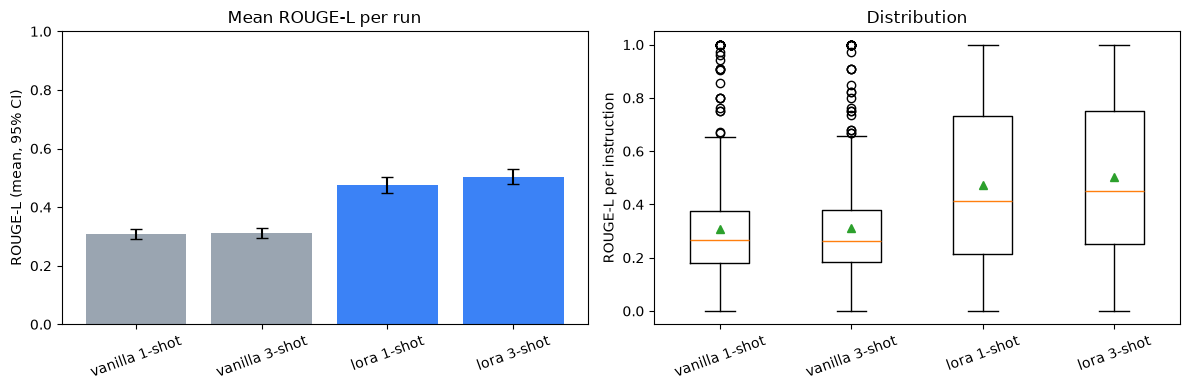

In [14]:
table = pd.DataFrame({name: rows['rouge_l'] for name, rows in outputs.items()})


def mean_ci(values):
    rng = np.random.default_rng(SEED)
    v = values.to_numpy()
    return np.percentile(v[rng.integers(0, len(v), (BOOTSTRAP, len(v)))].mean(axis=1), [2.5, 97.5])


overview = pd.DataFrame({name: {'n': table[name].count(), 'mean': table[name].mean(),
                                'ci95_low': mean_ci(table[name])[0], 'ci95_high': mean_ci(table[name])[1],
                                'median': table[name].median(), 'zero': (table[name] == 0).mean(),
                                'perfect': (table[name] >= 0.999).mean()} for name in table}).T
display(overview.round(4))

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
names = list(overview.index)
left.bar(names, overview['mean'], yerr=[overview['mean'] - overview['ci95_low'], overview['ci95_high'] - overview['mean']],
         capsize=4, color=['#9aa5b1' if n.startswith('vanilla') else '#3b82f6' for n in names])
left.set_ylabel('ROUGE-L (mean, 95% CI)')
left.set_ylim(0, 1)
left.set_title('Mean ROUGE-L per run')
right.boxplot([table[n].dropna() for n in names], showmeans=True)
right.set_xticks(range(1, len(names) + 1), names)
right.set_ylabel('ROUGE-L per instruction')
right.set_title('Distribution')
for ax in (left, right):
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# Line per model over the number of shots: the slope is the shot effect, the gap between lines the adapter effect
fig, ax = plt.subplots(figsize=(6, 4))
for model, color in (('vanilla', '#9aa5b1'), ('lora', '#3b82f6')):
    points = [(k, f'{model} {k}-shot') for k in SHOTS if f'{model} {k}-shot' in overview.index]
    if not points:
        continue
    ks = [k for k, _ in points]
    mean = overview.loc[[n for _, n in points], 'mean'].to_numpy() * 100
    low = overview.loc[[n for _, n in points], 'ci95_low'].to_numpy() * 100
    high = overview.loc[[n for _, n in points], 'ci95_high'].to_numpy() * 100
    ax.plot(ks, mean, marker='o', color=color, label=model)
    ax.fill_between(ks, low, high, color=color, alpha=0.15)
    for k, m in zip(ks, mean):
        ax.annotate(f'{m:.1f}', (k, m), textcoords='offset points', xytext=(0, 8), ha='center', color=color)
ax.set_xticks(list(SHOTS), [f'{k}-shot' for k in SHOTS])
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(0, 100)
ax.set_ylabel('ROUGE-L (%, mean and 95% CI band)')
ax.set_title('CodeAlpaca-20k (500 instructions)')
ax.legend()
plt.tight_layout()
plt.savefig('bab4-shot-codealpaca.pdf', bbox_inches='tight')   # figure for Bab IV (thesis figures/)
plt.show()

## 4. Paired tests
Shot effect (0 vs 1, 1 vs 3, 0 vs 3 examples) within each model and adapter effect (LoRA vs vanilla) at each shot
count, one Holm family. `a_better` / `b_better` / `tie` count instructions.

In [16]:
tests = wilcoxon_family(table, PAIRS)
tests.round(4)

,comparison,n,mean_a,mean_b,mean_diff,ci95_low,ci95_high,median_diff,a_better,b_better,tie,p,rank_biserial,p_holm,significant
0,vanilla 3-shot − vanilla 1-shot,500,0.3108,0.3081,0.0026,-0.0072,0.0122,0.0000,218,192,90,0.1386,0.0844,0.1386,False
1,lora 3-shot − lora 1-shot,500,0.5037,0.4748,0.0289,0.0140,0.0444,0.0000,156,98,246,0.0000,0.3038,0.0001,True
2,lora 1-shot − vanilla 1-shot,500,0.4748,0.3081,0.1667,0.1411,0.1931,0.0929,325,152,23,0.0000,0.5604,0.0000,True
3,lora 3-shot − vanilla 3-shot,500,0.5037,0.3108,0.1930,0.1683,0.2181,0.1420,354,127,19,0.0000,0.6606,0.0000,True


## 5. Answer style
ROUGE-L compares tokens of the whole reply, so length, prose and code fences move it. Reference = CodeAlpaca `output`.

In [17]:
any_run = next(iter(outputs.values())) if outputs else None
style = {}
if any_run is not None:
    style['reference'] = {'mean_chars': any_run['reference'].str.len().mean(), 'code_fence': any_run['reference'].str.contains('```').mean(),
                          'exact_match': np.nan}
for name, rows in outputs.items():
    style[name] = {'mean_chars': rows['completion'].str.len().mean(), 'code_fence': rows['completion'].str.contains('```').mean(),
                   'exact_match': (rows['completion'].str.strip() == rows['reference'].str.strip()).mean()}
pd.DataFrame(style).T.round(3)

,mean_chars,code_fence,exact_match
reference,193.000,0.000,NaN
vanilla 1-shot,538.586,0.874,0.026
vanilla 3-shot,530.574,0.854,0.022
lora 1-shot,150.298,0.000,0.058
lora 3-shot,139.686,0.000,0.062


## 6. Examples
Instructions where the two sides of the most relevant comparison differ the most (adapter effect at 3 shots, or the
shot effect of LoRA if vanilla is not on the Hub yet).

In [18]:
a, b = ('lora 3-shot', 'vanilla 3-shot') if {'lora 3-shot', 'vanilla 3-shot'} <= set(table) else ('lora 3-shot', 'lora 1-shot')
if {a, b} <= set(table):
    diff = (table[a] - table[b]).sort_values()
    for idx in list(diff.index[:2]) + list(diff.index[-2:]):
        row = outputs[a].loc[idx]
        print('=' * 100)
        print(f'idx {idx} | {a} {table.at[idx, a]:.3f} | {b} {table.at[idx, b]:.3f}')
        print('INSTRUCTION:', row['instruction'], row['input'])
        print('--- reference ---', row['reference'], sep='\n')
        print(f'--- {a} ---', row['completion'], sep='\n')
        print(f'--- {b} ---', outputs[b].loc[idx, 'completion'], sep='\n')

idx 8122 | lora 3-shot 0.255 | vanilla 3-shot 0.822
INSTRUCTION: Create multiple classes in Java with the provided input. class Player {
    String name;
    int age;
    String club; 
    String position;
--- reference ---
class Player {
    String name; 
    int age;
    String club;
    String position;

    // Constructors
    public Player(String name, int age, String club, String position) {
        this.name = name;
        this.age = age;
        this.club = club;
        this.position = position;
    }
    
    // Getters and Setters
    public String getName() {
        return this.name;
    }
    public void setName(String name) {
        this.name = name;
    }
    public int getAge() {
        return this.age;
    }
    public void setAge(int age) {
        this.age = age;
    }
    public String getClub() {
        return this.club;
    }
    public void setClub(String club) {
        this.club = club;
    }
    public String getPosition() {
        return this.position;


## 7. Context: Nguyen et al. (IJECE 2026)
Their models were fine-tuned **on CodeAlpaca-20k itself**, so their replies follow the reference style; ours were
fine-tuned on Code4ML (or not at all) and see 0, 1 or 3 examples. Subset, ROUGE implementation and models also differ,
so this is an order-of-magnitude check, not a head-to-head comparison. Their "before" column (no fine-tuning) is the
closest match to `vanilla 0-shot`.

In [19]:
ours = overview[['mean']].rename(columns={'mean': 'rouge_l'}).assign(source='this POC (Qwen2.5-Coder-7B)')
theirs = NGUYEN.set_index('model')[['rouge_l_after']].rename(columns={'rouge_l_after': 'rouge_l'}).assign(
    source='Nguyen, after fine-tuning on CodeAlpaca')
pd.concat([ours, theirs]).round(3)

,rouge_l,source
vanilla 1-shot,0.308,this POC (Qwen2.5-Coder-7B)
vanilla 3-shot,0.311,this POC (Qwen2.5-Coder-7B)
lora 1-shot,0.475,this POC (Qwen2.5-Coder-7B)
lora 3-shot,0.504,this POC (Qwen2.5-Coder-7B)
Qwen2.5-3B-Instruct,0.550,"Nguyen, after fine-tuning on CodeAlpaca"
Llama-3.2-3B-Instruct,0.540,"Nguyen, after fine-tuning on CodeAlpaca"
Gemma-2-2B-it,0.490,"Nguyen, after fine-tuning on CodeAlpaca"
Llama-3.2-1B-Instruct,0.460,"Nguyen, after fine-tuning on CodeAlpaca"
Qwen2.5-1.5B-Instruct,0.460,"Nguyen, after fine-tuning on CodeAlpaca"


## 8. Reading the results
- **Shot effect** (`k-shot − 0-shot`, `3-shot − 1-shot`): significant and positive = examples help on general
  programming; compare the direction with Code4ML / DS-1000.
- **Adapter effect** (`lora − vanilla`): not significant = the Code4ML adapter neither helps nor hurts general
  programming; significantly negative = it trades general ability for the ML domain; significantly positive = the
  adapter mostly teaches a reply style (bare code) that ROUGE-L rewards — check section 5 before calling it ability.
- ROUGE-L measures token overlap with one reference, not correctness.